# G25AIT2080_flowers — Tokenization & Vectorization

This notebook is the original *flowers* neural network, rebuilt so that:

1. **Tokenization** — each flower is stored as a text record and split into tokens.
2. **Vocabulary & encoding** — tokens are mapped to integer IDs.
3. **Vectorization** — the tokens become a NumPy feature matrix.



In [1]:
%matplotlib inline
from matplotlib import pyplot as plt
import numpy as np
import re
from collections import Counter

## 1. Raw data as text

In [2]:
raw_data = [
    "length: 3   width: 1.5 type: red",
    "length: 2   width: 1   type: blue",
    "length: 4   width: 1.5 type: red",
    "length: 3   width: 1   type: blue",
    "length: 3.5 width: .5  type: red",
    "length: 2   width: .5  type: blue",
    "length: 5.5 width: 1   type: red",
    "length: 1   width: 1   type: blue",
]

mystery_flower_text = "length: 4.5 width: 1"
raw_data

['length: 3   width: 1.5 type: red',
 'length: 2   width: 1   type: blue',
 'length: 4   width: 1.5 type: red',
 'length: 3   width: 1   type: blue',
 'length: 3.5 width: .5  type: red',
 'length: 2   width: .5  type: blue',
 'length: 5.5 width: 1   type: red',
 'length: 1   width: 1   type: blue']

## 2. Tokenization

In [3]:
TOKEN_PATTERN = re.compile(r"[a-z]+|\d*\.\d+|\d+")

def tokenize(text):
    return TOKEN_PATTERN.findall(text.lower())

tokenized = [tokenize(t) for t in raw_data]
mystery_tokens = tokenize(mystery_flower_text)

for text, toks in zip(raw_data, tokenized):
    print(f"{text!r:40} -> {toks}")
print()
print("mystery:", mystery_tokens)

'length: 3   width: 1.5 type: red'       -> ['length', '3', 'width', '1.5', 'type', 'red']
'length: 2   width: 1   type: blue'      -> ['length', '2', 'width', '1', 'type', 'blue']
'length: 4   width: 1.5 type: red'       -> ['length', '4', 'width', '1.5', 'type', 'red']
'length: 3   width: 1   type: blue'      -> ['length', '3', 'width', '1', 'type', 'blue']
'length: 3.5 width: .5  type: red'       -> ['length', '3.5', 'width', '.5', 'type', 'red']
'length: 2   width: .5  type: blue'      -> ['length', '2', 'width', '.5', 'type', 'blue']
'length: 5.5 width: 1   type: red'       -> ['length', '5.5', 'width', '1', 'type', 'red']
'length: 1   width: 1   type: blue'      -> ['length', '1', 'width', '1', 'type', 'blue']

mystery: ['length', '4.5', 'width', '1']


## 3. Vocabulary & token IDs

In [4]:
counts = Counter(tok for toks in tokenized for tok in toks)
vocab = {tok: i for i, tok in enumerate(sorted(counts))}
id_to_token = {i: tok for tok, i in vocab.items()}

print("vocab size:", len(vocab))
print(vocab)
print()
token_ids = [[vocab[t] for t in toks] for toks in tokenized]
for toks, ids in zip(tokenized, token_ids):
    print(toks, "->", ids)

vocab size: 13
{'.5': 0, '1': 1, '1.5': 2, '2': 3, '3': 4, '3.5': 5, '4': 6, '5.5': 7, 'blue': 8, 'length': 9, 'red': 10, 'type': 11, 'width': 12}

['length', '3', 'width', '1.5', 'type', 'red'] -> [9, 4, 12, 2, 11, 10]
['length', '2', 'width', '1', 'type', 'blue'] -> [9, 3, 12, 1, 11, 8]
['length', '4', 'width', '1.5', 'type', 'red'] -> [9, 6, 12, 2, 11, 10]
['length', '3', 'width', '1', 'type', 'blue'] -> [9, 4, 12, 1, 11, 8]
['length', '3.5', 'width', '.5', 'type', 'red'] -> [9, 5, 12, 0, 11, 10]
['length', '2', 'width', '.5', 'type', 'blue'] -> [9, 3, 12, 0, 11, 8]
['length', '5.5', 'width', '1', 'type', 'red'] -> [9, 7, 12, 1, 11, 10]
['length', '1', 'width', '1', 'type', 'blue'] -> [9, 1, 12, 1, 11, 8]


### Bag-of-words vectors

In [5]:
def bag_of_words(tokens, vocab):
    v = np.zeros(len(vocab), dtype=int)
    for t in tokens:
        if t in vocab:
            v[vocab[t]] += 1
    return v

bow = np.array([bag_of_words(t, vocab) for t in tokenized])
print("columns:", [id_to_token[i] for i in range(len(vocab))])
print(bow)

columns: ['.5', '1', '1.5', '2', '3', '3.5', '4', '5.5', 'blue', 'length', 'red', 'type', 'width']
[[0 0 1 0 1 0 0 0 0 1 1 1 1]
 [0 1 0 1 0 0 0 0 1 1 0 1 1]
 [0 0 1 0 0 0 1 0 0 1 1 1 1]
 [0 1 0 0 1 0 0 0 1 1 0 1 1]
 [1 0 0 0 0 1 0 0 0 1 1 1 1]
 [1 0 0 1 0 0 0 0 1 1 0 1 1]
 [0 1 0 0 0 0 0 1 0 1 1 1 1]
 [0 2 0 0 0 0 0 0 1 1 0 1 1]]


## 4. Vectorization + Required Matrix Multiplication



In [6]:
LABELS = {"blue": 0, "red": 1}
FEATURES = ["length", "width"]

def tokens_to_fields(tokens):
    return {tokens[i]: tokens[i + 1] for i in range(0, len(tokens) - 1, 2)}

def vectorize(tokens):
    fields = tokens_to_fields(tokens)
    x = np.array([float(fields[f]) for f in FEATURES])
    y = LABELS[fields["type"]] if "type" in fields else None
    return x, y

pairs = [vectorize(t) for t in tokenized]
X = np.vstack([p[0] for p in pairs])
y = np.array([p[1] for p in pairs], float)
mystery_flower, _ = vectorize(mystery_tokens)

data = [[X[i,0], X[i,1], y[i]] for i in range(len(y))]


A = np.array([
    [1, 2, 3, 4, 5],
    [6, 7, 8, 9, 10],
    [11, 12, 13, 14, 15]
])
print("\nMatrix A (3 × 5):")
print(A)
print("Shape of A:", A.shape)


B = np.array([
    [1, 2],
    [3, 4],
    [5, 6],
    [7, 8],
    [9, 10]
])
print("\nMatrix B (5 × 2):")
print(B)
print("Shape of B:", B.shape)


output = A @ B
print("\nOutput Matrix (3 × 2) = A @ B:")
print(output)
print("Shape of Output:", output.shape)




Matrix A (3 × 5):
[[ 1  2  3  4  5]
 [ 6  7  8  9 10]
 [11 12 13 14 15]]
Shape of A: (3, 5)

Matrix B (5 × 2):
[[ 1  2]
 [ 3  4]
 [ 5  6]
 [ 7  8]
 [ 9 10]]
Shape of B: (5, 2)

Output Matrix (3 × 2) = A @ B:
[[ 95 110]
 [220 260]
 [345 410]]
Shape of Output: (3, 2)


## 5. Scatter plot

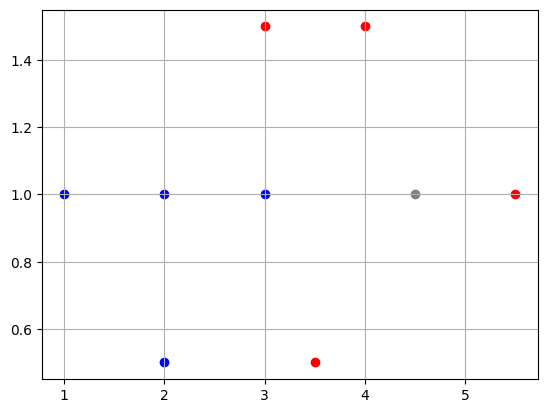

In [7]:
def vis_data():
    plt.grid()
    for i in range(len(data)):
        c = 'r' if data[i][2] == 1 else 'b'
        plt.scatter([data[i][0]], [data[i][1]], c=c)
    plt.scatter([mystery_flower[0]], [mystery_flower[1]], c='gray')

vis_data()

## 6. Network (same style as original flowers.ipynb)

In [8]:
def sigmoid(x):
    return 1/(1 + np.exp(-x))

def sigmoid_p(x):
    return sigmoid(x) * (1 - sigmoid(x))

## 7. Training

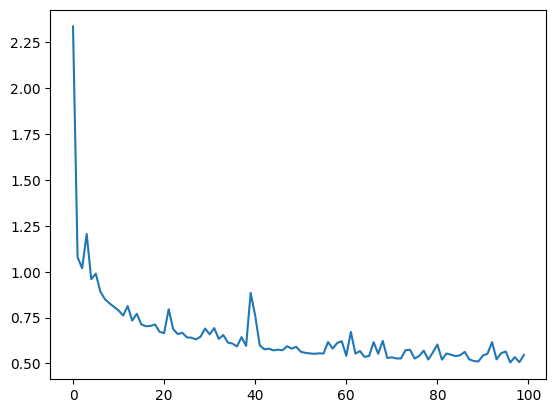

In [9]:
def train():
    w1 = np.random.randn()
    w2 = np.random.randn()
    b  = np.random.randn()

    iterations = 10000
    learning_rate = 0.1
    costs = []

    for i in range(iterations):
        ri = np.random.randint(len(data))
        point = data[ri]

        z = point[0] * w1 + point[1] * w2 + b
        pred = sigmoid(z)
        target = point[2]

        if i % 100 == 0:
            c = 0
            for j in range(len(data)):
                p = data[j]
                p_pred = sigmoid(w1 * p[0] + w2 * p[1] + b)
                c += np.square(p_pred - p[2])
            costs.append(c)

        dcost_dpred = 2 * (pred - target)
        dpred_dz = sigmoid_p(z)
        dcost_dz = dcost_dpred * dpred_dz

        w1 = w1 - learning_rate * dcost_dz * point[0]
        w2 = w2 - learning_rate * dcost_dz * point[1]
        b  = b  - learning_rate * dcost_dz * 1

    return costs, w1, w2, b

costs, w1, w2, b = train()
plt.plot(costs)

## 8. Predict the mystery flower

In [10]:
z = w1 * mystery_flower[0] + w2 * mystery_flower[1] + b
pred = sigmoid(z)

print(pred)
print("close to 0 → blue, close to 1 → red")

0.9925416781621094
close to 0 → blue, close to 1 → red


## 9. Decision boundary

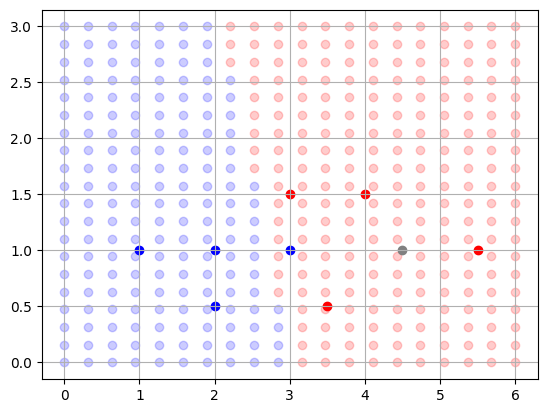

In [11]:
for x in np.linspace(0, 6, 20):
    for y in np.linspace(0, 3, 20):
        pred = sigmoid(w1 * x + w2 * y + b)
        c = 'r' if pred > 0.5 else 'b'
        plt.scatter([x], [y], c=c, alpha=0.2)

vis_data()

## 10. Classify new flowers from text

In [12]:
def classify(text):
    x, _ = vectorize(tokenize(text))
    z = w1 * x[0] + w2 * x[1] + b
    p = sigmoid(z)
    return p, ("red" if p > 0.5 else "blue")

for t in ["length: 4.5 width: 1", "length: 1.5 width: .8", "length: 6 width: 2"]:
    p, label = classify(t)
    print(f"{t:25} → {p:.4f} ({label})")

length: 4.5 width: 1      → 0.9925 (red)
length: 1.5 width: .8     → 0.0279 (blue)
length: 6 width: 2        → 0.9999 (red)
